# What does “quiet” look like in one guitar recording?

Work through one cell at a time. This lesson measures background level in **one** C take. It does not automatically find a note's start/end or change the comparison script.

Choose **Guitar ML (.venv)** as the kernel after setup. Run from the Guitar_ML project folder.

## 1. Load the recording
The file supplies its sample rate. At 44,100 Hz, each channel has 44,100 amplitude measurements per second. We use the left channel consistently.


In [1]:
from pathlib import Path
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

file_path = Path("data/raw/C_note_dry_take01.wav")
if not file_path.exists():
    raise FileNotFoundError("Run this lesson from the Guitar_ML project folder.")
samples, sample_rate = sf.read(file_path)
signal = samples[:, 0] if samples.ndim == 2 else samples
sample_indices = np.arange(len(signal))
time_seconds = sample_indices / sample_rate

print("Sample rate:", sample_rate, "samples per second per channel")
print("Array shape:", samples.shape)
print("Duration:", round(len(signal) / sample_rate, 3), "seconds")


Sample rate: 44100 samples per second per channel
Array shape: (458620, 2)
Duration: 10.4 seconds


## 2. Look before deciding
The waveform shows individual signed amplitudes. Locate the quiet lead-in and the strong attack. A flat-looking line at this scale can still contain background noise.


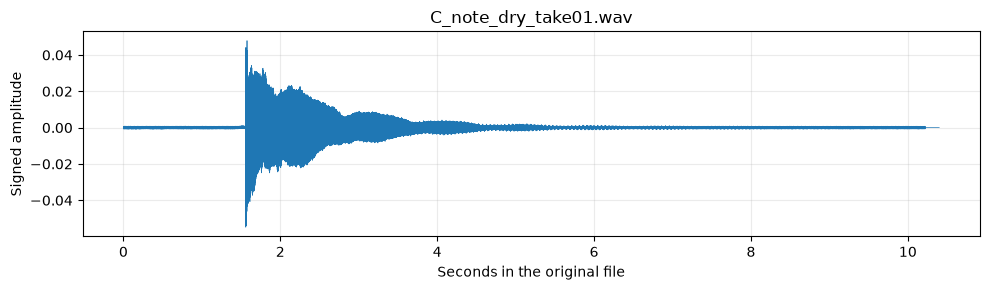

In [2]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(time_seconds, signal, linewidth=0.5)
ax.set(xlabel="Seconds in the original file", ylabel="Signed amplitude",
       title=file_path.name)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 3. Select a candidate quiet interval
For **this take**, 0.20–1.00 seconds is before the visible attack. These are editable selections, not a universal silence duration. Only use a region where you were not playing; an image alone cannot prove it contains no faint note.

Seconds × sample rate gives a sample index. Python's slice includes the start and excludes the stop. At 44,100 Hz, this selection is `signal[8820:44100]`.


Candidate quiet slice: signal[8820:44100]
Samples selected: 35280


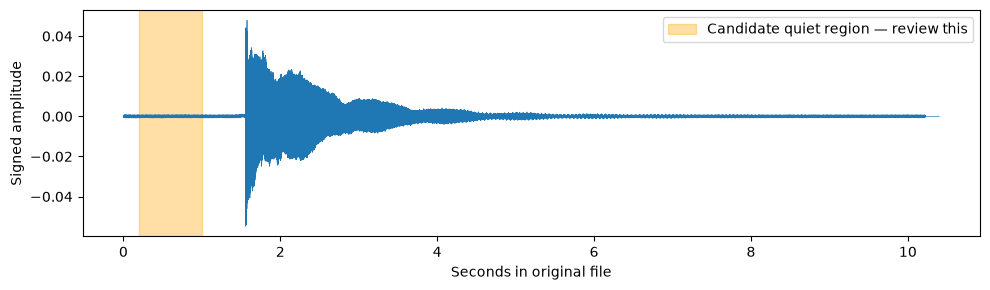

In [3]:
quiet_start_seconds = 0.20
quiet_end_seconds = 1.00
quiet_start = round(quiet_start_seconds * sample_rate)
quiet_stop = round(quiet_end_seconds * sample_rate)
if not 0 <= quiet_start < quiet_stop <= len(signal):
    raise ValueError("Choose a nonempty quiet interval inside this recording.")

print(f"Candidate quiet slice: signal[{quiet_start}:{quiet_stop}]")
print("Samples selected:", quiet_stop - quiet_start)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(time_seconds, signal, linewidth=0.5)
ax.axvspan(quiet_start / sample_rate, quiet_stop / sample_rate,
           color="orange", alpha=0.35, label="Candidate quiet region — review this")
ax.set(xlabel="Seconds in original file", ylabel="Signed amplitude")
ax.legend()
fig.tight_layout()
plt.show()


## 4. Calculate ONE window by following the arithmetic
A 50 ms window contains 2,205 samples at 44,100 Hz. It is a useful starting resolution, not a law: shorter windows show faster changes; longer windows smooth them.

RMS = square root of the mean of the squared amplitudes. Squaring prevents positive and negative values from cancelling. Here are those operations separately.


In [4]:
window_seconds = 0.05
window_samples = round(window_seconds * sample_rate)
if quiet_stop - quiet_start < window_samples:
    raise ValueError("Choose a quiet region at least one window long.")

one_window = signal[quiet_start:quiet_start + window_samples]
squared_samples = one_window ** 2
mean_square = np.mean(squared_samples)
one_window_rms = np.sqrt(mean_square)

print("Samples in this window:", len(one_window))
print("Mean square:", mean_square)
print("RMS:", one_window_rms)


Samples in this window: 2205
Mean square: 2.5577370136503188e-08
RMS: 0.0001599292660412821


## 5. Repeat exactly that calculation across the recording
The loop advances by `window_samples` each time. Each plotted time is the window's midpoint in the original file. A partial final window is dropped, not filled with zeros.

For the background estimate we retain only windows **fully inside** your selected quiet interval. A window crossing its boundary is excluded.


In [5]:
window_starts = np.arange(0, len(signal) - window_samples + 1, window_samples)
window_stops = window_starts + window_samples
rms_values = []

for start, stop in zip(window_starts, window_stops):
    window = signal[start:stop]
    rms_values.append(np.sqrt(np.mean(window ** 2)))

rms_values = np.array(rms_values)
window_times = (window_starts + window_samples / 2) / sample_rate
inside_quiet = (window_starts >= quiet_start) & (window_stops <= quiet_stop)
quiet_rms = rms_values[inside_quiet]
if len(quiet_rms) < 3:
    raise ValueError("Select a longer quiet region with at least three complete windows.")

print("Quiet-window RMS values:", quiet_rms)
print("Median (middle value):", np.median(quiet_rms))
print("Highest observed quiet-window RMS:", np.max(quiet_rms))


Quiet-window RMS values: [0.00015993 0.00015787 0.00016081 0.00016201 0.00015728 0.0001585
 0.00015801 0.00015571 0.00015555 0.00015496 0.00015564 0.00015884
 0.00015586 0.00015479 0.00015827 0.00015296]
Median (middle value): 0.00015757507689776818
Highest observed quiet-window RMS: 0.00016200741298957248


## 6. Draw a candidate threshold, then question it
For a transparent first experiment, set the threshold to **1.5 × the largest RMS in the selected quiet region**. That means 50% above the largest background window we observed. The multiplier is an adjustable guess, not a scientifically established boundary or a confidence level.

It sits above the selected background by construction. That alone does **not** validate it: it might still react to noise elsewhere or miss a soft attack. A candidate region containing a click may make this threshold too high.

The top plot shows the whole recording; the bottom magnifies only the selected background windows. Their vertical scales differ intentionally. Original amplitudes are unchanged.


Candidate RMS threshold: 0.00024301111948435872


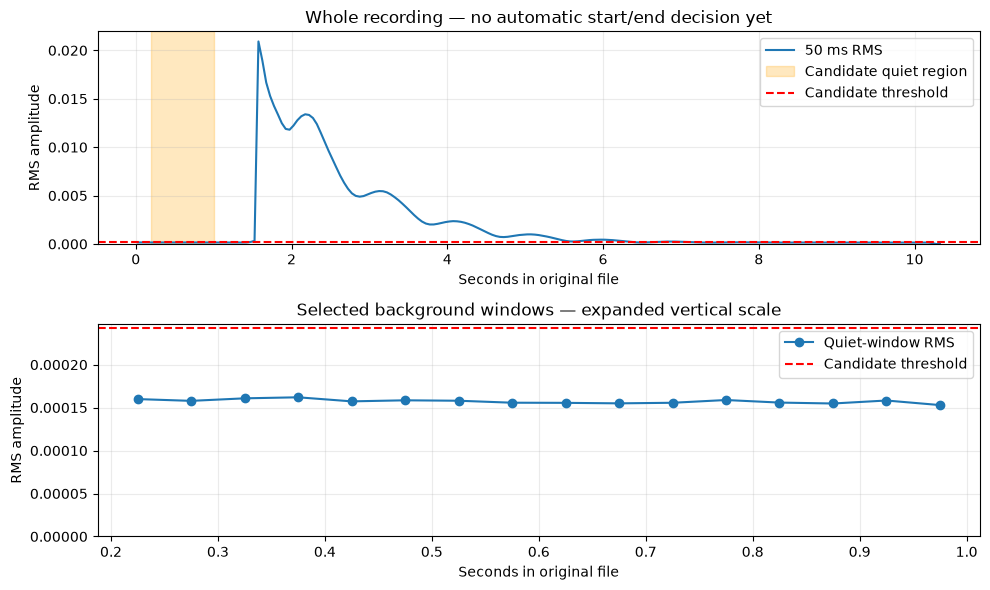

In [6]:
threshold_multiplier = 1.5
candidate_threshold = threshold_multiplier * np.max(quiet_rms)
print("Candidate RMS threshold:", candidate_threshold)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
axes[0].plot(window_times, rms_values, label="50 ms RMS")
axes[0].axvspan(quiet_start / sample_rate, quiet_stop / sample_rate,
               color="orange", alpha=0.25, label="Candidate quiet region")
axes[0].set_title("Whole recording — no automatic start/end decision yet")
axes[1].plot(window_times[inside_quiet], quiet_rms, "o-", label="Quiet-window RMS")
axes[1].set_title("Selected background windows — expanded vertical scale")
for ax in axes:
    ax.axhline(candidate_threshold, color="red", linestyle="--", label="Candidate threshold")
    ax.set(xlabel="Seconds in original file", ylabel="RMS amplitude")
    ax.set_ylim(bottom=0)
    ax.legend()
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Stop here and interpret
- Why isn't background RMS zero?
- If you move the quiet interval, which values must be recalculated?
- Does the selected interval really contain only background? The program cannot know your playing intent.

Next, review another known quiet interval and the soft part of the note against this candidate threshold. Then we can discuss how long a change must persist before calling it a start or an end. No automatic note-end detector or benchmark claim is made in this lesson.


## 7. Check the same threshold on A take01, 0–1.2 seconds
You confirmed that you were not playing during this interval. This gives us a **new background region** to check, separate from the C region used to choose the threshold.

Keep the C-based threshold unchanged. Recalculating it from A first would defeat this check. Each A window is still 50 ms long, converted using A's own sample rate.

At 44,100 Hz, the selected interval is samples `0:52920`: 24 complete windows of 2,205 samples each. A quiet window above the threshold would be a false alarm for a simple window-by-window sound rule.


In [7]:
c_threshold = float(candidate_threshold)
a_path = Path("data/raw/A_note_dry_take01.wav")
a_samples, a_sample_rate = sf.read(a_path)
a_signal = a_samples[:, 0] if a_samples.ndim == 2 else a_samples

a_quiet_start_seconds = 0.0
a_quiet_end_seconds = 1.2
a_start = round(a_quiet_start_seconds * a_sample_rate)
a_stop = round(a_quiet_end_seconds * a_sample_rate)
a_window_size = round(window_seconds * a_sample_rate)
if not 0 <= a_start < a_stop <= len(a_signal):
    raise ValueError("The selected A interval must be inside the recording.")

a_window_starts = np.arange(a_start, a_stop - a_window_size + 1, a_window_size)
a_quiet_rms = []
for start in a_window_starts:
    window = a_signal[start:start + a_window_size]
    a_quiet_rms.append(np.sqrt(np.mean(window ** 2)))
a_quiet_rms = np.array(a_quiet_rms)
if len(a_quiet_rms) == 0:
    raise ValueError("The selected A interval needs at least one complete window.")

a_above_threshold = a_quiet_rms > c_threshold
print(f"A quiet slice: a_signal[{a_start}:{a_stop}]")
print("Window size:", a_window_size, "samples")
print("Number of windows:", len(a_quiet_rms))
print(f"A quiet RMS min / median / max: {a_quiet_rms.min():.8f} / "
      f"{np.median(a_quiet_rms):.8f} / {a_quiet_rms.max():.8f}")
print(f"Unchanged C threshold: {c_threshold:.8f}")
print(f"Quiet A windows above threshold: {a_above_threshold.sum()} / {len(a_quiet_rms)}")
for index in np.flatnonzero(a_above_threshold):
    start = int(a_window_starts[index])
    stop = start + a_window_size
    print(f"Above threshold: samples [{start}:{stop}], "
          f"{start / a_sample_rate:.2f}–{stop / a_sample_rate:.2f} seconds")


A quiet slice: a_signal[0:52920]
Window size: 2205 samples
Number of windows: 24
A quiet RMS min / median / max: 0.00016459 / 0.00016922 / 0.00026708
Unchanged C threshold: 0.00024301
Quiet A windows above threshold: 1 / 24
Above threshold: samples [46305:48510], 1.05–1.10 seconds


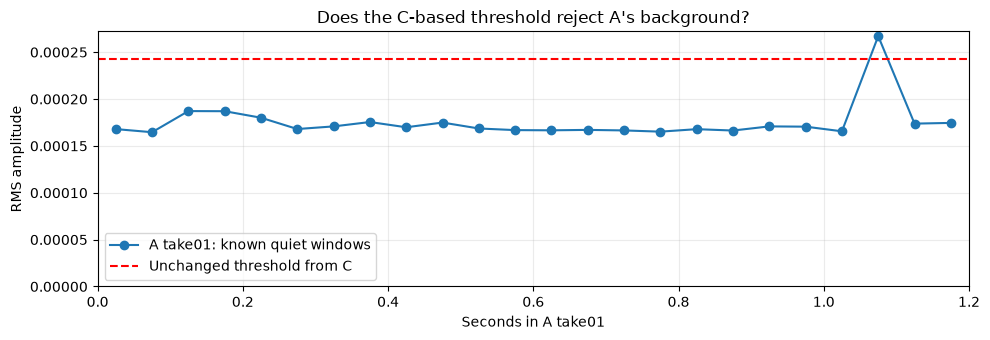

In [8]:
a_window_times = (a_window_starts + a_window_size / 2) / a_sample_rate
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(a_window_times, a_quiet_rms, "o-", label="A take01: known quiet windows")
ax.axhline(c_threshold, color="red", linestyle="--", label="Unchanged threshold from C")
ax.set(xlabel="Seconds in A take01", ylabel="RMS amplitude",
       title="Does the C-based threshold reject A's background?", xlim=(0, 1.2))
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


### Result for these recordings
**1 of 24 known-quiet windows exceeded the unchanged C-based threshold.** It covers 1.05–1.10 seconds, original samples `46305:48510`, with RMS about 0.00026708 versus the threshold of 0.00024301.

The other 23 windows stayed below the line. This isolated excursion is a false alarm for a rule that labels every above-threshold window as a note. Its physical cause has not been identified; we cannot call it a click or guitar note from RMS alone.

These adjacent windows come from one recording, not 24 independent sessions. This result does not estimate a general false-alarm rate or prove that the rule will detect quiet notes.

Next, inspect the flagged waveform interval. Then consider whether requiring a rise to persist across multiple windows would reject this excursion while still detecting the note's attack. That duration rule has not been added here. Keep the threshold fixed while studying this example rather than adjusting it to force a pass.


## 8. A strong rise that lasts: one start-detection experiment
The previous section tested a C-derived absolute threshold on A's background. Leave that result intact. Here we try a **separate, explicitly provisional rule** for isolated picked notes:

1. Estimate this recording's typical background using the median of its user-confirmed quiet windows (A, 0–1.2 seconds).
2. Divide each window's RMS by that background level. A ratio of 1 means typical background; 10 means ten times its RMS amplitude, not ten times perceived loudness.
3. Require a ratio above **10 for two consecutive 50 ms windows**.

Ten times background is an intentionally conservative trial for clearly picked notes; 100 ms is short compared with our sustained notes but longer than one isolated window. Neither setting is established as optimal. Keep these settings fixed when testing new D/G takes; report errors before changing them. Quiet-region selection remains manual, not a fixed lead-in assumption.

The median is the middle value after sorting; it is less affected by the one high background window than the maximum. This is not a formal signal-to-noise-ratio calculation: the measured windows contain signal plus noise.


In [9]:
background_rms = np.median(a_quiet_rms)
if background_rms <= 0:
    raise ValueError("The selected background is zero; choose a genuine noise-only interval.")

strength_ratio = 10.0
required_windows = 2
all_a_starts = np.arange(0, len(a_signal) - a_window_size + 1, a_window_size)
all_a_rms = []
for start in all_a_starts:
    window = a_signal[start:start + a_window_size]
    all_a_rms.append(np.sqrt(np.mean(window ** 2)))
all_a_rms = np.array(all_a_rms)
relative_rms = all_a_rms / background_rms
strong = relative_rms > strength_ratio

first_run = None
for index in range(len(strong) - required_windows + 1):
    if np.all(strong[index:index + required_windows]):
        first_run = index
        break

print(f"Median background RMS: {background_rms:.8f}")
print(f"Trial RMS threshold: {strength_ratio * background_rms:.8f}")
print("Required duration:", required_windows * a_window_size / a_sample_rate, "seconds")
if first_run is None:
    print("No sustained start found under this trial rule.")
else:
    start_sample = int(all_a_starts[first_run])
    confirmation_sample = start_sample + required_windows * a_window_size
    print(f"Candidate start-window boundary: sample {start_sample}, "
          f"{start_sample / a_sample_rate:.3f} seconds")
    print(f"Enough evidence available at sample {confirmation_sample}, "
          f"{confirmation_sample / a_sample_rate:.3f} seconds")
    print("Ratios in the confirming windows:", relative_rms[first_run:first_run + required_windows])
print("Highest ratio in the known quiet interval:", np.max(a_quiet_rms / background_rms))


Median background RMS: 0.00016922
Trial RMS threshold: 0.00169218
Required duration: 0.1 seconds
Candidate start-window boundary: sample 88200, 2.000 seconds
Enough evidence available at sample 92610, 2.100 seconds
Ratios in the confirming windows: [39.89937431 93.73609189]
Highest ratio in the known quiet interval: 1.5783378535548807


### Start estimate versus confirmation time
We must wait for both windows to finish before confirming the rise. We then mark the **beginning of the first qualifying window**, not the later confirmation time.

That is a window boundary expressed as an original-file sample index, **not a sample-accurate attack measurement**. The attack can occur partway through a window, and a soft beginning may be missed. Smaller windows or later sample-level refinement could improve timing, but first understand this simple rule.


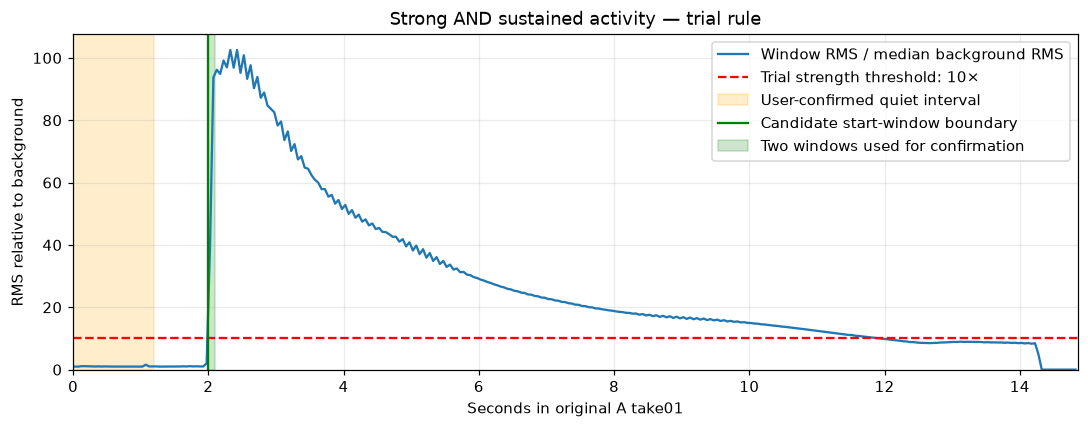

In [10]:
all_a_times = (all_a_starts + a_window_size / 2) / a_sample_rate
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(all_a_times, relative_rms, label="Window RMS / median background RMS")
ax.axhline(strength_ratio, color="red", linestyle="--", label="Trial strength threshold: 10×")
ax.axvspan(a_start / a_sample_rate, a_stop / a_sample_rate,
           color="orange", alpha=0.2, label="User-confirmed quiet interval")
if first_run is not None:
    ax.axvline(start_sample / a_sample_rate, color="green", label="Candidate start-window boundary")
    ax.axvspan(start_sample / a_sample_rate, confirmation_sample / a_sample_rate,
               color="green", alpha=0.2, label="Two windows used for confirmation")
ax.set(xlabel="Seconds in original A take01", ylabel="RMS relative to background",
       title="Strong AND sustained activity — trial rule", xlim=(0, len(a_signal) / a_sample_rate))
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


### Pause and explain the loop
Why do we mark the start of the first strong window rather than the end of the second?

This is a development example on a recording we have already inspected, not a held-out validation. The quiet excursion is below the new strength threshold, so rejecting it does not by itself demonstrate the value of persistence. Sustained handling noise could still pass both conditions, and quiet or short real notes could fail.

**This is a start rule only.** Do not use the 10× line to declare the end of a fading note: it would discard quieter ringing that is still above background. End detection needs a separately explained rule. The batch comparison script remains unchanged.
